# 07 · Live decoding: what the explorer's Decode tab does, step by step

**What this notebook is for.** It goes with explorer update 2. The explorer now decodes the errors *you* click, one step at a time,
with three decoders: a lookup table, minimum-weight matching (MWPM) and BP + OSD. Those browser decoders are a JavaScript copy of our
Python decoders (`explorer/decoders.js`). This notebook:

1. follows the same examples in Python, with a picture at every step (syndrome → graph → matching → correction → what is left);
2. shows the two ways matching can still fail: a **tie** and a **too-heavy** error;
3. watches BP go round in circles on the gross code and OSD rescue it;
4. checks, on hundreds of random errors, that the browser decoders give **exactly** the Python answers.

Requires Node.js for part 4 (it skips politely otherwise).

In [1]:
import sys, pathlib, json, shutil, subprocess
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
from qdec.families import catalogue
from qdec.views import draw_lattice, draw_matching, draw_osd_steps
from qdec.dem import MatchingGraph, DecodingProblem
from qdec.decoders import MWPMDecoder, BPOSDDecoder
from qdec.bp import MinSumBP
from qdec.export import code_to_dict
CODES = {c.name: c for c in catalogue()}
FIG = pathlib.Path("../docs/figures")
def xvec(code, qubits):
    """0/1 vector with X errors on the given qubits."""
    e = np.zeros(code.n, np.uint8); e[list(qubits)] = 1; return e

## 1 · The syndrome: all the decoder gets

Three X errors on the rotated surface code (d = 5). The Z checks that contain an odd number of them light up. That pattern of lit checks
(the ancillas reading 1) is the **only** input a decoder has.

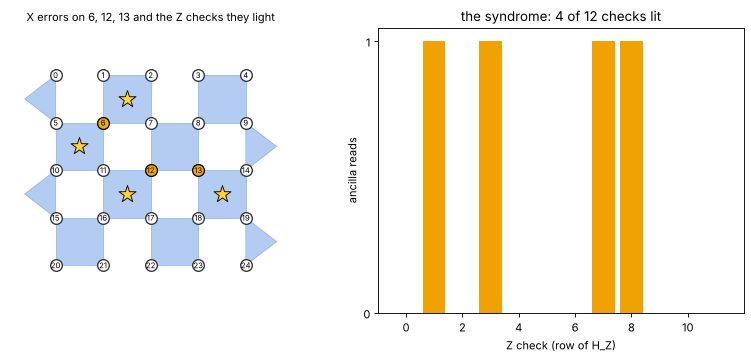

In [2]:
sd5 = CODES["surface (rotated) d=5"]
err = [6, 12, 13]
fig, axs = plt.subplots(1, 2, figsize=(10, 4.6))
draw_lattice(sd5, axs[0], show="Z", error_x=xvec(sd5, err), title="X errors on 6, 12, 13 and the Z checks they light")
s = sd5.HZ.astype(int) @ xvec(sd5, err) % 2
axs[1].bar(range(len(s)), s, color=["#f0a202" if v else "#cfd5df" for v in s])
axs[1].set_xlabel("Z check (row of H_Z)"); axs[1].set_ylabel("ancilla reads"); axs[1].set_yticks([0, 1])
axs[1].set_title(f"the syndrome: {s.sum()} of {len(s)} checks lit")
plt.tight_layout(); plt.show()

## 2 · Matching: pair up the lit checks as cheaply as possible

Every qubit is an **edge** between the (one or two) Z checks that contain it; a qubit in only one check is an edge to the **boundary**.
A string of X errors lights only its two ends, so the decoder looks for the set of paths that pairs up all lit checks (or sends them to the
boundary) with the smallest total length. Three outcomes are possible, and the next figure shows one of each:

* **exact**: the paths are your error;
* **degeneracy**: the paths are *different* from your error but the difference is a stabilizer, so nothing is wrong;
* **logical error**: the difference is a logical operator. Your error was heavier than half the distance, so the other way round was shorter.

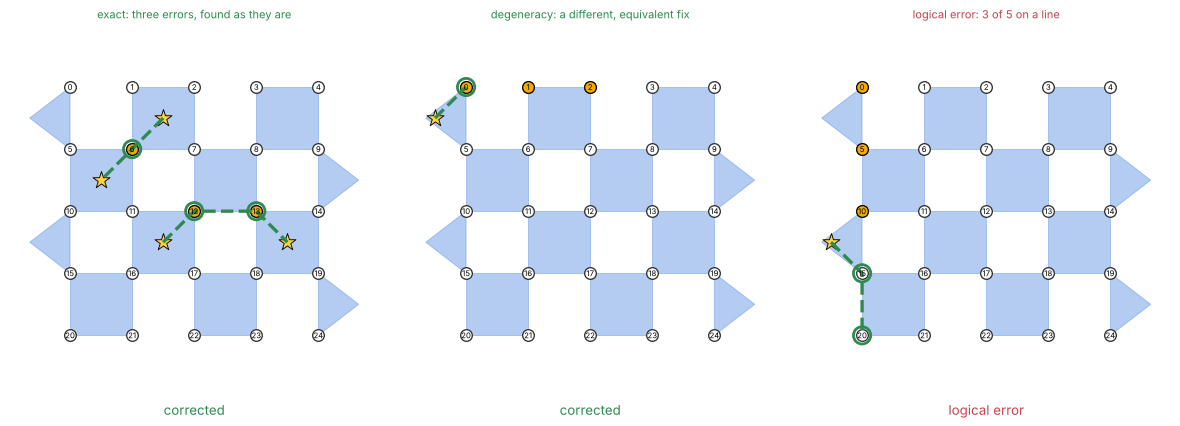

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, (e, t) in zip(axs, [([6, 12, 13], "exact: three errors, found as they are"),
                             ([0, 1, 2], "degeneracy: a different, equivalent fix"),
                             ([0, 5, 10], "logical error: 3 of 5 on a line")]):
    _, bad = draw_matching(sd5, xvec(sd5, e), ax=ax, title=t)
    ax.set_xlabel("logical error" if bad else "corrected", color="#c4424f" if bad else "#2f8a4f", fontsize=12)
plt.tight_layout(); fig.savefig(FIG / "39_matching_three_outcomes.png", dpi=110, bbox_inches="tight"); plt.show()

**Why the third one fails.** Errors on 0, 5, 10 are three steps of a five-qubit column. Lit: only the check after qubit 10.
The cheapest explanation is the two qubits from there to the bottom boundary (15, 20). Error × correction = the whole column = a logical X̄.
With distance 5, any ⌊(5−1)/2⌋ = 2 errors are always safe; 3 can fail.

## 3 · A tie: two equally short fixes

On the 4 × 4 torus, X errors on two neighbouring qubits of a row (2 and 3) light two checks. Joining them takes 2 flips the way the errors
went, and **also** 2 flips the other way around the torus. Matching cannot tell these apart, picks one, and here it picks the wrong one.
Error weight 2 = d/2 is exactly the point where ties appear.

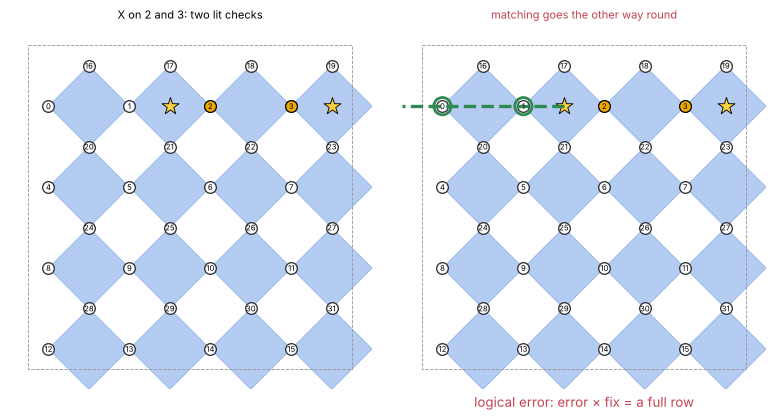

In [4]:
tor = CODES["toric 4x4"]
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
draw_lattice(tor, axs[0], show="Z", error_x=xvec(tor, [2, 3]), title="X on 2 and 3: two lit checks")
_, bad = draw_matching(tor, xvec(tor, [2, 3]), ax=axs[1], title="matching goes the other way round")
axs[1].set_xlabel("logical error: error × fix = a full row" if bad else "corrected", color="#c4424f" if bad else "#2f8a4f", fontsize=12)
plt.tight_layout(); fig.savefig(FIG / "40_toric_tie_wrong_way.png", dpi=110, bbox_inches="tight"); plt.show()

## 4 · When there is no graph: BP, then OSD

On the gross code each qubit sits in **three** Z checks, so one flip lights three checks: a hyperedge, and matching does not apply.
Belief propagation passes messages between checks and qubits instead. On this weight-4 error it does not settle: the number of
unexplained checks goes up and down forever.

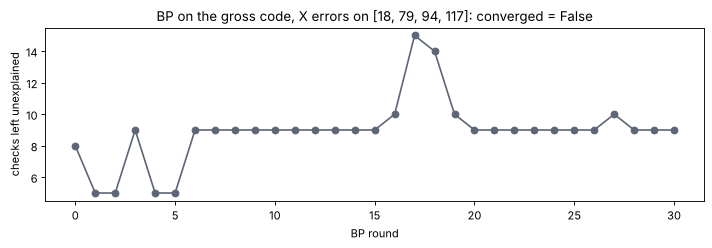

In [5]:
gross = CODES["gross [[144,12,12]]"]
gerr = [18, 79, 94, 117]
bp = MinSumBP(gross.HZ, 0.05, max_iter=30, alpha=0.625)
res = bp.decode(gross.HZ.astype(int) @ xvec(gross, gerr) % 2)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(res.unsatisfied_history, "o-", color="#5d6677")
ax.set_xlabel("BP round"); ax.set_ylabel("checks left unexplained")
ax.set_title(f"BP on the gross code, X errors on {gerr}: converged = {res.converged}")
plt.tight_layout(); fig.savefig(FIG / "41_gross_bp_unsatisfied.png", dpi=110, bbox_inches="tight"); plt.show()

OSD takes BP's belief **averaged over all rounds**, sorts qubits from most to least likely flipped, and solves the check equations
using the most trusted independent qubits. The three panels: average belief, the qubits OSD keeps, OSD's answer vs the truth.

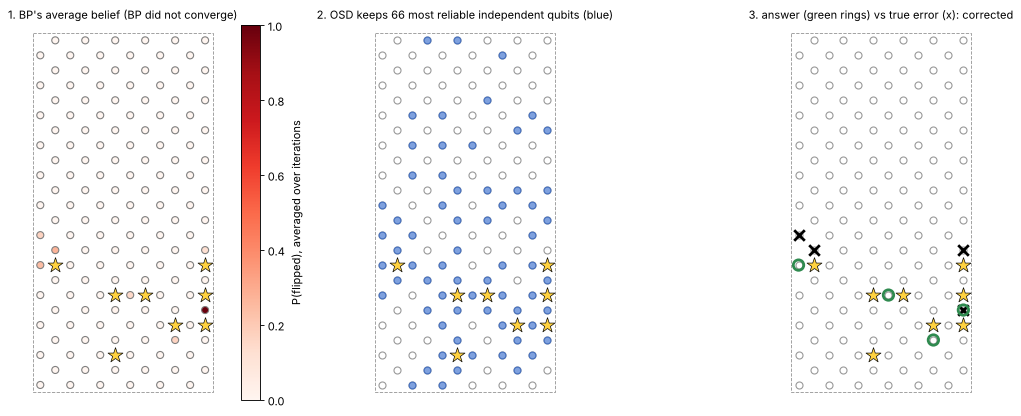

OSD correction: [1, 23, 85, 117] | logical error: False


In [6]:
dec = BPOSDDecoder(DecodingProblem.code_capacity(gross.HZ, np.zeros((1, gross.n), np.uint8), 0.05), max_iter=30, osd_order=0)
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2))
_, bad = draw_osd_steps(gross, xvec(gross, gerr), dec, axs=axs)
plt.tight_layout(); plt.show()
corr = dec.decode_error(gross.HZ.astype(int) @ xvec(gross, gerr) % 2)
print("OSD correction:", np.nonzero(corr)[0].tolist(), "| logical error:", bad)

OSD's answer is **not** your exact error, but error × correction is a stabilizer (the explorer says "Corrected … degeneracy").

## 5 · The browser decoders give exactly the Python answers

`explorer/decoders.js` is a separate implementation, so it must be checked. We run it in Node on random errors and compare:

* **MWPM**: same matched pairs, same total weight (to 1e-9);
* **BP**: same belief on every qubit at every round (to 1e-9);
* **BP + OSD-0**: the same correction, qubit for qubit.

The same comparison runs in `tests/test_explorer_decoders.py`.

In [7]:
NODE = shutil.which("node") or ("/opt/node22/bin/node" if pathlib.Path("/opt/node22/bin/node").exists() else None)
JS = pathlib.Path("../explorer/decoders.js").resolve()
DRIVER = r'''
const Q = require(process.argv[process.argv.length - 1]);
let b = ""; process.stdin.on("data", d => b += d).on("end", () => {
  const j = JSON.parse(b), out = [];
  for (const c of j.cases) { const e = new Set(c);
    if (j.what === "mwpm") { const r = Q.mwpm(j.code, e, "Z"); out.push([r.cost, r.pairs.map(p => [p.a, p.b])]); }
    else if (j.what === "bp") out.push(Q.bp(j.code, e, "Z", 0.05, 30, 0.625).llr);
    else out.push([...Q.bposd(j.code, e, "Z", 0.05, 30, 0.625).correction].sort((a, b) => a - b)); }
  process.stdout.write(JSON.stringify(out)); });'''
def js(code, cases, what):
    job = {"code": code_to_dict(code, dist={"d": None, "how": ""}), "cases": cases, "what": what}
    r = subprocess.run([NODE, "-e", DRIVER, str(JS)], input=json.dumps(job), capture_output=True, text=True, check=True)
    return json.loads(r.stdout)

rng = np.random.default_rng(7)
def cases(code, N=150, wmax=6):
    return [sorted(int(q) for q in rng.choice(code.n, int(rng.integers(1, wmax + 1)), replace=False)) for _ in range(N)]

rows = []
if NODE:
    for name in ["surface (rotated) d=5", "surface (unrotated) d=5", "toric 4x4"]:
        c = CODES[name]; cs = cases(c); out = js(c, cs, "mwpm")
        g = MatchingGraph.from_check_matrix(c.HZ, np.zeros((1, c.n), np.uint8), 0.05); d = MWPMDecoder(g)
        zr = list(c.index_of("Z")); same = 0
        for e, (cost, pairs) in zip(cs, out):
            d.decode(c.HZ.astype(int) @ xvec(c, e) % 2)
            py = sorted((zr[a], None if b == g.boundary else zr[b]) for a, b in d.last_matching)
            same += sorted(tuple(p) for p in pairs) == py
        rows.append(("MWPM", name, same, len(cs)))
    for name in ["toric 4x4", "BB [[72,12,6]]", "gross [[144,12,12]]"]:
        c = CODES[name]; cs = cases(c, 100, 8)
        bp = MinSumBP(c.HZ, 0.05, max_iter=30, alpha=0.625)
        out = js(c, cs, "bp")
        same = sum(np.allclose(np.array(l), bp.decode(c.HZ.astype(int) @ xvec(c, e) % 2).llr_history, atol=1e-9) for e, l in zip(cs, out))
        rows.append(("BP", name, same, len(cs)))
        dec = BPOSDDecoder(DecodingProblem.code_capacity(c.HZ, np.zeros((1, c.n), np.uint8), 0.05), max_iter=30, osd_order=0)
        out = js(c, cs, "bposd")
        same = sum(o == np.nonzero(dec.decode_error(c.HZ.astype(int) @ xvec(c, e) % 2))[0].tolist() for e, o in zip(cs, out))
        rows.append(("BP+OSD", name, same, len(cs)))
    for r in rows: print(f"{r[0]:7s} {r[1]:26s} {r[2]}/{r[3]} identical")
else:
    print("Node.js not found: skipping the comparison")

MWPM    surface (rotated) d=5      150/150 identical
MWPM    surface (unrotated) d=5    150/150 identical
MWPM    toric 4x4                  150/150 identical
BP      toric 4x4                  100/100 identical
BP+OSD  toric 4x4                  100/100 identical
BP      BB [[72,12,6]]             100/100 identical
BP+OSD  BB [[72,12,6]]             100/100 identical
BP      gross [[144,12,12]]        100/100 identical
BP+OSD  gross [[144,12,12]]        100/100 identical


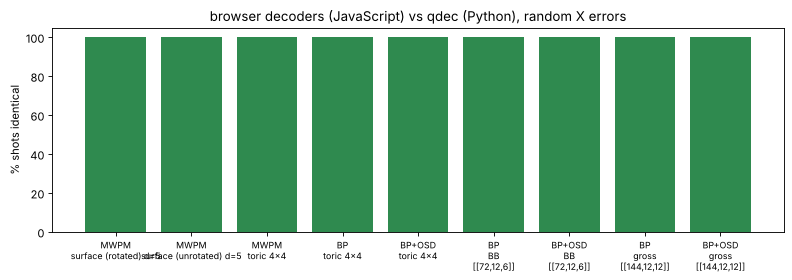

In [8]:
if rows:
    fig, ax = plt.subplots(figsize=(10, 3.6))
    labels = [f"{a}\n{b.replace(' [[', chr(10) + '[[')}" for a, b, *_ in rows]
    ax.bar(range(len(rows)), [100 * s / n for _, _, s, n in rows], color="#2f8a4f")
    ax.set_xticks(range(len(rows)), labels, fontsize=8); ax.set_ylim(0, 105); ax.set_ylabel("% shots identical")
    ax.set_title("browser decoders (JavaScript) vs qdec (Python), random X errors")
    plt.tight_layout(); fig.savefig(FIG / "46_js_vs_python_agreement.png", dpi=110, bbox_inches="tight"); plt.show()

## 6 · The same thing in the explorer

Open `explorer/index.html`, go to **Decode**, and click an example (or click qubits yourself). Next / Back walk through the steps above.

![Surface d=5, matching: step 4 of 6, the second pair is being matched (thick dashes). Only the Z checks (blue) are shown, because only they see X errors.](../docs/figures/42_explorer_decode_matching.png)

*Surface d=5, matching: step 4 of 6, the second pair is being matched (thick dashes). Only the Z checks (blue) are shown, because only they see X errors.*

![Toric tie, result: the residual (error × correction) is a full row, a logical X̄₀.](../docs/figures/43_explorer_decode_toric_tie.png)

*Toric tie, result: the residual (error × correction) is a full row, a logical X̄₀.*

![Gross code, BP round 12 of 30: the slider and the curve of unexplained checks under the picture.](../docs/figures/44_explorer_decode_gross_bp.png)

*Gross code, BP round 12 of 30: the slider and the curve of unexplained checks under the picture.*

![Gross code, OSD: the 8 qubits BP trusts most (on average) are numbered; the four real errors are among them.](../docs/figures/45_explorer_decode_gross_osd.png)

*Gross code, OSD: the 8 qubits BP trusts most (on average) are numbered; the four real errors are among them.*

## What we learned

* A decoder only sees the syndrome. Matching turns it into a shortest-paths puzzle; BP into a message-passing guess; OSD into exact linear algebra in a smart order.
* "Not the same as my error" is fine when the difference is a stabilizer (**degeneracy**); it is a failure only when the difference is a logical.
* Matching fails on **ties** (weight d/2) and on errors heavier than (d−1)/2. BP fails by **freezing** on ties and **oscillating** on qLDPC codes; OSD rescues both.
* The browser decoders are tested to give identical answers to the Python ones, so what you click is what the library does.

**Next (explorer unit 3):** the Stim circuit beside the lattice: click a check to see its ancilla and its CNOTs, and open Stim's own diagram on demand.

**References.** Dennis, Kitaev, Landahl & Preskill, J. Math. Phys. 43, 4452 (2002) (matching for the surface code) · Edmonds, Can. J. Math. 17, 449 (1965) (matching) ·
Higgott & Gidney, arXiv:2303.15933 (PyMatching v2) · Panteleev & Kalachev, Quantum 5, 585 (2021) (BP+OSD) · Roffe et al., Phys. Rev. Research 2, 043423 (2020), arXiv:2005.07016 ·
Bravyi et al., Nature 627, 778 (2024) (gross code).